In [1]:
from load_file_kenzie import load_archive

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import LinearLocator
from matplotlib.ticker import FormatStrFormatter
import matplotlib as mpl
import os,copy
from tqdm import tqdm
from matplotlib import colors
import numpy.ma as ma
import pandas as pd
from station_colors import get_station_colors

In [3]:
def normalise(ds, t_cent, bw, n_chan, tele, on_mask=None, t_sig=None):
    """
    Calibrate the dynamic spectrum for the bandpass
    Per frequency channel it subtracts the off burst mean and divides by the off burst std
    The input is the dynamic spectrum where the time of the on-burst is cutout and masked
    """

    # on_mask is True where things are masked
    #We mask the part where the burst is in time, from start to end
    #on_mask[:, s:e] = True
    ds_off = np.ma.masked_array(ds, mask=on_mask)

    #Mask channels where the value is zero and mask the channels where the boolean list is True
    ds_off_masked = np.ma.masked_where(ds_off == 0.00, ds_off)

    #Normalise the spectrum
    ds_corrected = (ds - ds_off_masked.mean(axis=1)[:,None]) / ds_off_masked.std(axis=1)[:, None]

    return ds_corrected

In [4]:
def SN(ts, t_cent, on_mask=None, t_sig=None):
    #ts_off = np.concatenate((ts[0:int(t_cent-3*t_sig)],ts[int(t_cent+3*t_sig):]))

    # duplicate the on-mask which comes as 2D but have it apply to a time series only
    on_mask_t = on_mask.T.mean(axis=-1)
    ts_off = np.ma.masked_array(ts, mask=on_mask_t)

    ts -= np.mean(ts_off)
    ts_off -= np.mean(ts_off)
    ts /= np.std(ts_off)
    ts_off /= np.std(ts_off)

    return ts, on_mask_t

In [10]:
def plot(ds, extent, tsamp, n_chan, tele, plot_grid_idx, fig, width,
         burst_n, nrows, ncols, nbursts, index,
         t_cent, f_cent,
         t_start, t_end,
         t_sig=None, f_sig=None,
         plot_spectrum=False, colour='cyan',
         t_cent_2=None,t_sig_2=None,f_cent_2=None,f_sig_2=None,
         obs_band="L"):
    """
    Creates the family burst plot
    This version supports L- and P-band bursts
    """
    
    freq_bottom = extent[2]
    bw = extent[3]-extent[2]


    #Creating the mask for the on burst part to normalise
    on_mask = np.zeros_like(ds, dtype=bool)
    for s, e in zip(t_start, t_end):
        on_mask[:, s:e] = True

    #function to normalise/standardize the data
    ds_norm = normalise(ds, t_cent, bw, n_chan, tele, on_mask)

    # on_mask is True where the pulse in 'on', masked entries
    # are those where the mask is True. Thus the 'off' mask is
    # the inverse of on_maks
    ds_norm_on = np.ma.masked_array(ds_norm, mask=~on_mask)

    #Calculate the spectrum of the burst, grep left and right in time
    spectrum = np.mean(ds_norm_on, axis=-1)

    #frequency resolution
    res_f = (extent[3]-extent[2])/spectrum.size 

    if t_cent_2:
        t_cent_1 = np.min([t_cent,t_cent_2])
        if t_cent_2 == t_cent_1:
            t_cent_2 = t_cent
            t_sig_1 = t_sig_2
            t_sig_2 = t_sig
        else:
            t_sig_1 = t_sig

        t_cent = (t_cent_2-t_cent_1)/2. + t_cent_1

    if f_cent_2:
        f_cent_1 = np.min([f_cent,f_cent_2])
        if f_cent_2 == f_cent_1:
            f_cent_2 = f_cent
            f_sig_1 = f_sig_2
            f_sig_2 = f_sig
        else:
            f_sig_1 = f_sig
        f_cent = (f_cent_2-f_cent_1)/2.+ f_cent_1

    if f_cent and f_sig:
        f_l_bin = int(np.ceil((f_cent-2.*f_sig)))# - extent[2])/res_f))
        if f_sig_2:
            f_l_bin = int(np.ceil((f_cent_1-2.*f_sig_1)))

        if f_l_bin < 0:
            f_l_bin = 0
        f_h_bin = int(np.ceil((f_cent+2.*f_sig)))# - extent[2])/res_f))
        if f_sig_2:
            f_h_bin = int(np.ceil((f_cent_2+2.*f_sig_2)))
        if f_h_bin > spectrum.size:
            f_h_bin = spectrum.size
    else:
        f_l_bin = 0
        f_h_bin = spectrum.size

    #bw = (f_h_bin - f_l_bin)*res_f #MHz

    #Create time window for burst, redfine the extent
    peak = np.int(np.ceil(t_cent))
    extent[0] = - width / 2. # width is time window around the burst
    extent[1] = width / 2.

    #time bins of burst around window
    t_l_bin = int(t_cent - (width/2.)/(tsamp*1e3))
    t_h_bin = int(t_cent + (width/2.)/(tsamp*1e3))
    if t_l_bin < 0 or t_h_bin > ds_norm.shape[1]:
        print(f'\n\n Careful with the on-times, we are rolling.\n')
        ds_norm = np.roll(ds_norm, int(ds_norm.shape[1]/2.-t_cent), axis=1)
        on_mask = np.roll(on_mask, int(ds_norm.shape[1]/2.-t_cent), axis=1)

        t_start_offsets = t_start - t_cent
        t_end_offsets = t_end - t_cent

        t_cent = int(ds_norm.shape[1]/2.)

        t_start =  t_cent + t_start_offsets
        t_end = t_cent + t_end_offsets
        t_h_bin = int(t_cent + (width/2.)/(tsamp*1e3))
        t_l_bin = int(t_cent - (width/2.)/(tsamp*1e3))

    #Time series
    ts = np.mean(ds_norm[f_l_bin:f_h_bin,:], axis=0) # time series (summed the frequencies) around the burst
    ts, on_mask_t = SN(ts, t_cent, on_mask)
    ds_norm = ds_norm[:,t_l_bin:t_h_bin]
    on_mask = on_mask[:,t_l_bin:t_h_bin]
    ts = ts[t_l_bin:t_h_bin]
    print(f't_l_bin: {t_l_bin}; t_cent: {t_cent}; t_h_bin: {t_h_bin}')
    on_mask_t = on_mask_t[t_l_bin:t_h_bin]
    t_start -= int(t_cent)
    t_end -= int(t_cent)
    print(f'After fiddling: t_start = {t_start}\nt_end={t_end}')
    print(f'In time units: t_start = {t_start*(tsamp*1e3)}\nt_end={t_end*(tsamp*1e3)}')
    x = (np.arange(t_l_bin,t_h_bin,1)-int(t_cent))*tsamp*1e3
    print(f'x_min = {x.min()}\nx_max = {x.max()}')
    
    #Gridspec in Gridspec
    rows = 2
    cols = 1
    if plot_spectrum: cols += 1
    plot_grid = gridspec.GridSpecFromSubplotSpec(rows, cols, plot_grid_idx, wspace=0., hspace=0.,
                                                 height_ratios=[1,]*(rows-1)+[2,], width_ratios=[5,]+[1,]*(cols-1))
    ax1 = plt.Subplot(fig, plot_grid[rows-1,0])
    ax2 = plt.Subplot(fig, plot_grid[rows-2,0], sharex=ax1)
    if plot_spectrum: ax3 = plt.Subplot(fig, plot_grid[rows-1,1], sharey=ax1)
    units = ("GHz", "ms")

    ###
    #Markers
    ###
    #We need to copy the colormap, old command not usable anymore #cmap = plt.cm.viridis
    cmap = copy.copy(mpl.cm.get_cmap("viridis"))
    
    #We replace the mask values with nan values, so we can use nanpercentile
    #setting up quantiles, using quantiles we can supress the super bright and dim parts of the dynamic spectrum
    #this way the constrast of the plot improves and the burst is better visible.
    #We first replace the masking with nans, because we can then use nanpercentile
    replace_masked = ds_norm.filled(np.nan)
    quantiles = np.nanpercentile(replace_masked, (0.05, 99.5))

    #Plotting the dynamic spectrum
    #We first plot the dynamic spectrum and afterwards overplot the red ticks
    ax1.imshow(replace_masked, cmap=cmap, origin='lower', aspect='auto', interpolation='nearest',
               vmin=quantiles[0], vmax=quantiles[1],extent=extent)
    
    #size of the red marker, 1 if full freq channel, 0 is no red mask -> just an int
    #We now make it 1/18th of the x-axis
    zap_size = int(ds_norm.shape[1]/18)

    #identifying the frequency channels that where zapped, only need a 1-D boolean list
    zapped = ma.getmaskarray(ds_norm[:,1])

    #We take the bins where the red marker will be and replace the mask with values of 9999
    #We do this because we want to asign a individual color map to these values
    zapped_marker = ds_norm[zapped,:zap_size]
    zapped_marker_mask_value = 9999 
    ds_norm[zapped,:zap_size] = ma.filled(zapped_marker,fill_value=zapped_marker_mask_value)

    #Here we create the colormap of red
    cm1 = mpl.colors.ListedColormap(['red'])

    #This is a boolean 2d array wehre values of 9999 at True
    mask_marker = ds_norm==zapped_marker_mask_value

    #We now create a 2D masked array where the values are NOT 9999, so we have a masked array with only True's
    #This means that we only make the marker red, the white spaces in the plot at part of the original mask
    mask_marker = ma.masked_where(mask_marker==False,mask_marker)

    #plotting the red markers for the masked channels
    ax1.imshow(mask_marker, cmap=cm1, origin='lower', aspect='auto', interpolation='nearest', extent=extent)

    #Set limits
    ax1.set_xlim(extent[0]-0.0001, extent[1]+0.0001)
    ax1.set_ylim(extent[2],extent[3])

    #Label only edge plots
    print(f"index and columns: {index}, {ncols}")
    if index % ncols == 0:
        
        if obs_band == "P":
            ax1.set_ylabel(r'${\rm Frequency}\ ({\rm MHz})$')
            
        if obs_band == "L" or obs_band == "subset":
            ax1.set_ylabel(r'${\rm Frequency}\ ({\rm GHz})$')
            
        ax2.set_ylabel('S/N')

    ax1.tick_params(axis='x', labelbottom=False)
    ax1.yaxis.set_major_locator(LinearLocator(numticks=4))
    
    #Setting the units of GHz and Mhz, seperate for L- and P-band
    if obs_band == "L" or obs_band=="subset":
        devide = 1000
        y_ticks_ghz = ax1.get_yticks() / devide
        y_ticks_ghz_round = np.around(y_ticks_ghz, decimals=2)
        ax1.set_yticklabels(y_ticks_ghz_round)
    
    elif obs_band == "P":
        y_ticks_mhz = ax1.get_yticks()
        y_ticks_mhz_round = np.asarray(y_ticks_mhz, dtype = 'int')
        
        print(f"ncols: {ncols}")
        if index % ncols == 0:
            ax1.set_yticklabels(y_ticks_mhz_round)
            
        else:
            ax1.set_yticklabels([])

    #Label only edge plots for Pband or subset
    if obs_band == "subset":
        burst_sep_x = ["B96-st", "B101-wb", "B120-wb", "B128-wb"]
        
    elif obs_band == "P":
        burst_sep_x = ["B131-st", "B132-tr", "B116-st", "B129-st"]
       
    #Just for clarity for a furture reader
    elif obs_band == "L":
        burst_sep_x = []
        
    if index >= ncols * (nrows-1) or burst_n in burst_sep_x:
        ax1.tick_params(axis='x', labelbottom=True)
        ax1.set_xlabel(r'${\rm Time}\ ({\rm ms})$')
        
    #But for P-band, label all figures
    if obs_band == "P":
        ax1.tick_params(axis='x', labelbottom=True)
        ax1.set_xlabel(r'${\rm Time}\ ({\rm ms})$')

    #Setting the ticks locators for the x-axis
    if obs_band == "L" or obs_band=="subset":
        ax1.xaxis.set_minor_locator(MultipleLocator(5))
    
    elif obs_band == "P":
        ax1.xaxis.set_minor_locator(MultipleLocator(50))

    ##Plotting SNR ax2
    #plot pulse profile (time series)
    ax2.plot(x, ts, 'k-',alpha=1.0,zorder=1,lw=0.5, drawstyle='steps-mid')
    point = ax2.scatter(x[0], ts[0], facecolors='none', edgecolors='none')

    #Setting ranges for SNR
    y_range = ts.max() - ts.min()
    ax2.set_ylim(-y_range/3., ts.max()*1.1)
    maxSN = np.ceil(np.max(ts))

    #only add 2 ticks
    yticks_sn=np.array([0,maxSN])
    ax2.set_yticks(yticks_sn)
    
    #Add 3 ticks to the y-axis
    #if maxSN % 2 == 0:
        #yticks_sn=np.array([0,maxSN/2.,maxSN])
    #else:
        #yticks_sn=np.array([0,(maxSN+1)/2.,maxSN])

    if t_sig_2:
        #ax2.hlines(y=-y_range/3.,xmin=(-(t_cent-t_cent_1+t_sig_1*2)*(tsamp*1e3)),xmax=((t_cent_2-t_cent+t_sig_2*2)*(tsamp*1e3)), lw=10,color=colour,zorder=0.8, alpha=0.2)
        ax2.hlines(y=-y_range/3.,xmin=(-(t_cent-t_cent_1+t_sig_1)*(tsamp*1e3)),xmax=((t_cent_2-t_cent+t_sig_2)*(tsamp*1e3)), lw=10,color=colour,zorder=0.8) #, alpha=0.4)
    else:
        #ax2.hlines(y=-y_range/3.,xmin=(-t_sig*2*(tsamp*1e3)),xmax=(t_sig*2*(tsamp*1e3)), lw=10,color=colour,zorder=0.8, alpha=0.2)
        ax2.hlines(y=[-y_range/3.]*len(t_start),
                   xmin=(t_start*(tsamp*1e3)), xmax=(t_end*(tsamp*1e3)),
                   lw=10, color=colour, zorder=0.8) #, alpha=0.4)

    #b = np.argmin(np.abs(x-(-t_sig*2*(tsamp*1e3))))
    #e = np.argmin(np.abs(x-(t_sig*2*(tsamp*1e3))))
    
    if t_sig_2:
        b = np.argmin(np.abs(x-(-((t_cent-t_cent_1)+t_sig_1*2)*(tsamp*1e3))))
        e = np.argmin(np.abs(x-((t_cent_2-t_cent+t_sig_2*2)*(tsamp*1e3))))

    box = ax2.get_position()
    ax2.set_position([box.x0, box.y0, box.width*0.6, box.height])
    legend1=ax2.legend((point,point), ((r"${\rm %s}$")%burst_n,""),
                       loc='upper left',handlelength=0,bbox_to_anchor=(0.01, 1.05),
                       handletextpad=-0.5,frameon=False,markerscale=0, fontsize = 6)
    ax2.add_artist(legend1)
    ax2.tick_params(labelbottom=False, labeltop=False, labelleft=True, labelright=False,
                    bottom=True, top=False, left=True, right=False)

    if obs_band == "L" or obs_band == "subset":
        time_res_set = fr"{int(tsamp*1e6)} $\mu$s"
        
    elif obs_band == "P":
        time_res_set = fr"{(tsamp*1e3):.3f} ms"
        
    if obs_band == "subset":
        x_position_text_box = 0.70
    else:
        x_position_text_box = 0.65
        
    legend2=ax2.legend((point,point), ((time_res_set),""),
                       loc='upper left',handlelength=0,bbox_to_anchor=(x_position_text_box, 1.05),
                       handletextpad=-0.5,frameon=False,markerscale=0,fontsize=6)
    ax2.add_artist(legend2)

    legend3=ax2.legend((point,point), ((f"{res_f:.2f} MHz"),""), loc='upper left',
                       handlelength=0,bbox_to_anchor=(x_position_text_box, 0.9), handletextpad=-0.5,
                       frameon=False,markerscale=0,fontsize=6)
    ax2.add_artist(legend3)

    ax2.tick_params(axis='y', which='major', pad=1.5)

    ##Plotting spectrum ax3
    #plot spectrum (amplitude vs freq) only if plot_spectrum=True
    if plot_spectrum:
        y = np.linspace(extent[2], extent[3], spectrum.size)
        ax3.plot(spectrum, y, 'k-',zorder=2, lw=0.7,drawstyle='steps-post')
        ax3.set_ylim(extent[2],extent[3])
        x_range = spectrum.max() - spectrum.min()
        ax3.set_xlim(-x_range/3., x_range*6./5.)

        #Setting up the ticks
        ax3.tick_params(labelleft=False, labelbottom=False, labeltop=False, labelright=False,                        bottom=False, top=False, left=True, right=False)
        ax3.tick_params(which="both", direction='in')
        #if f_sig_2:
        #    ax3.vlines(x=-x_range/3.,ymin=(extent[2]+(f_cent_1-2.*f_sig_1)*(res_f)),ymax=(extent[2]+(f_cent_2+2.*f_sig_2)*(res_f)), lw=20,color=colour,zorder=0.8, alpha=0.2)
        #    ax3.vlines(x=-x_range/3.,ymin=(extent[2]+(f_cent_1-f_sig_1)*(res_f)),ymax=(extent[2]+(f_cent_2+f_sig_2)*(res_f)), lw=20,color=colour,zorder=0.8, alpha=0.4)
        #    ax3.axhline(y=(extent[2]+(f_cent)*(res_f)),color=colour,lw=0.5)
        #else:
            #ax3.vlines(x=-x_range/3.,ymin=(extent[2]+(f_cent-2.*f_sig)*(res_f)),ymax=(extent[2]+(f_cent+2.*f_sig)*(res_f)), lw=20,color=colour,zorder=0.8, alpha=0.2)
            #ax3.vlines(x=-x_range/3.,ymin=(extent[2]+(f_cent-f_sig)*(res_f)),ymax=(extent[2]+(f_cent+f_sig)*(res_f)), lw=20,color=colour,zorder=0.8, alpha=0.4)
            #ax3.axhline(y=(extent[2]+(f_cent)*(res_f)),color=colour,lw=0.5)

    fig.add_subplot(ax1)
    fig.add_subplot(ax2)
    if plot_spectrum: fig.add_subplot(ax3)

    return

In [6]:
def prep_data(dataframe, band, mode='sfxc'):
    
    known_modes = ['sfxc', 'scale', 'spc']
    if not mode in known_modes:
        raise ValueError(f'Unknown mode {mode}. Chose from {known_modes}.')

    data = pd.read_csv(dataframe)
    data = data[(data.src == mode)]
    
    #Filter based on observing frequency    
    if band == "L":
        data = data[data['f0_MHz'] != 328]

        dropped=['B130-tr']
        data = data[~data['id'].isin(dropped)]
        
    elif band == "P":
        data = data[data['f0_MHz'] == 328]
        
    elif band =='subset':
        ids_subset = ["B08-st","B15-tr",'B15-wb',"B35-st",\
                  "B52-wb","B60-st","B68-wb","B77-st",\
                 "B96-st","B101-wb","B120-wb","B128-wb"]    
        data = data[data['id'].isin(ids_subset)]
        
    data.sort_values(by='toa_bary_tdb_inf_freq', ignore_index=True, inplace=True)
    ids = data.id.unique()
    
    return ids, data

In [7]:
def dict_maker_scrunch():

    """
    Dictionary with the tscrunch and fscrunch command per burst.
    For P-band an extra element is added: the width around the bursts to be plotted.
    """
    
    scr_dic = {

        #Lband bursts
        #[tscrunch, fscrunch]
        'B01-st' : [1,1],
        'B02-st' : [1,1], 
        'B03-st' : [4,2], 
        'B04-st' : [2,1],
        'B05-tr' : [1,1],
        'B06-tr' : [2,1],
        'B07-st' : [1,1],
        'B07-tr' : [1,1],
        'B08-st' : [1,1],
        'B09-st' : [1,1],
        'B10-st' : [1,1],
        'B11-st' : [1,1],
        'B12-st' : [1,1],
        'B13-st' : [1,1],
        'B13-tr' : [1,1],
        'B14-wb' : [4,8],
        'B15-tr' : [1,1],
        'B15-wb' : [1,1],
        'B16-tr' : [1,1],
        'B16-wb' : [1,2],
        #Check
        'B17-st' : [1,1],
        'B18-st' : [1,1],
        'B19-st' : [1,1],
        'B20-st' : [1,1],
        'B21-tr' : [2,2],
        'B22-wb' : [1,2],
        'B23-wb' : [2,2],
        'B24-wb' : [1,2],
        'B25-st' : [1,1],
        'B26-st' : [1,1],
        'B27-st' : [1,1],
        'B28-st' : [1,1],
        'B29-st' : [1,1],
        'B30-st' : [1,1],
        'B30-wb' : [1,2],
        'B31-st' : [1,1],
        'B32-st' : [1,1],
        'B33-wb' : [1,4],
        #Check
        'B34-st' : [1,1],
        'B35-st' : [1,1],
        'B36-st' : [1,1],
        'B37-tr' : [1,2],
        'B37-wb' : [1,2],
        'B38-st' : [1,1],
        'B39-st' : [1,1],
        'B40-st' : [1,1],
        'B41-st' : [1,1],
        'B42-st' : [1,1],
        'B43-st' : [1,1],
        'B44-wb' : [1,8],
        'B45-wb' : [1,8],
        'B46-wb' : [1,1],
        'B47-st' : [1,1],
        'B48-st' : [1,1],
        'B49-st' : [1,1],
        'B51-wb' : [1,1],
        'B50-st' : [1,1],
        'B52-wb' : [1,1],
        'B53-st' : [1,4],
        'B53-wb' : [1,8],
        #Check
        'B54-st' : [1,1],
        'B55-wb' : [2,4],
        'B56-st' : [1,1],
        'B57-st' : [1,1],
        'B58-st' : [1,1],
        'B59-st' : [1,1],
        'B60-st' : [1,1],
        'B61-st' : [1,1],
        'B62-st' : [1,1],
        'B63-st' : [1,4],
        'B63-wb' : [2,1],
        'B64-st' : [1,4],
        'B64-wb' : [1,1],
        'B65-st' : [1,1],
        'B66-wb' : [1,4],
        'B67-st' : [1,1],
        'B68-st' : [1,1],
        'B68-wb' : [1,1],
        #Check
        'B69-st' : [1,1],
        'B69-wb' : [1,1],
        'B70-wb' : [2,4],
        'B71-wb' : [2,4],
        'B72-wb' : [2,4],
        'B73-st' : [1,1],
        'B74-st' : [1,1],
        'B75-st' : [1,1],
        'B76-st' : [1,1],
        'B77-st' : [1,1],
        'B78-st' : [1,1],
        'B79-st' : [1,1],
        'B80-st' : [1,1],
        'B81-wb' : [4,16],
        'B82-st' : [1,1],
        'B82-wb' : [1,1],
        'B83-wb' : [1,1],
        'B85-st' : [1,1],
        'B85-wb' : [1,1],
        'B86-st' : [1,1],
        'B87-st' : [1,1],
        'B88-st' : [1,1],
        #Check
        'B89-st' : [1,1],
        'B90-st' : [2,1],
        'B91-st' : [1,1],
        'B92-st' : [1,1],
        'B93-st' : [1,1],
        'B94-st' : [1,1],
        'B95-st' : [1,1],
        'B96-st' : [1,1],
        'B97-tr' : [1,4],
        'B98-st' : [1,1],
        'B99-st' : [1,1],
        'B101-wb' : [1,1],
        'B102-st' : [1,1],
        'B103-wb' : [4,8],
        'B104-st' : [2,2],
        'B104-wb' : [4,8],
        'B105-wb' : [1,1],
        'B106-st' : [1,1],
        'B106-wb' : [1,1],
        'B107-st' : [1,1],
        #check
        'B107-wb' : [1,1],
        'B108-st' : [1,1],
        'B111-tr' : [1,1],
        'B112-st' : [1,1],
        'B113-st' : [1,1],
        'B114-st' : [1,1],
        'B116-st' : [1,1],
        'B129-st' : [1,1],
        'B131-st' : [1,1],
        'B132-tr' : [1,1],
        
        #P-band [tscrunch, fscrunch, width_burst]
        #f-res = 3.9 Khz, plot= 125 KHz, factor 
        'B100-wb' : [8,16,500],
        'B109-wb' : [8,16,500],
        'B110-wb' : [8,16,500],
        'B115-wb' : [4,16,250],
        'B117-wb' : [4,16,250],
        'B118-wb' : [8,32,500],
        'B119-wb' : [8,16,500],
        'B120-wb' : [1,8,100],
        'B121-wb' : [1,8,100],
        'B122-wb' : [4,16,350],
        'B123-wb' : [4,16,350],
        'B124-wb' : [16,16,1000],
        'B125-wb' : [4,16,400],
        'B126-wb' : [4,16,350],
        'B127-wb' : [4,16,500],
        'B128-wb' : [1,8,100]
    } 
    
    return scr_dic
    
scr_dic = dict_maker_scrunch()

In [8]:
def controller(obs_band, width_burst):
    
    #The figure has been made to hold 4x5, changing this would make the dynamic spectra streched
    nrows = 5
    ncols = 4

    #grid of burst plots
    #wspace and hspace is the space between plots
    if obs_band == "L" or obs_band=="subset":
        h_space = 0.1
        w_space = 0.3
        
    elif obs_band == "P":
        h_space = 0.14
        w_space = 0.15
        
    #adapt the figure parameters as needed:
    #Time window around the burst in ms. This value is overwritten in case for P-band in the for-loop
    if obs_band == "L" or obs_band=="subset":
        b_width = width_burst 
        
    plot_grid = gridspec.GridSpec(nrows, ncols, wspace=w_space, hspace=h_space)

    # base directory
    base_dir = '/data1/omar/'

    ids, data = prep_data('/home/omar/git/r117-single-dish-analysis/dbs/burst_stats_r117.csv', band=obs_band)
    idx = 0
    
    #if obs_band == "L":
       #ids =  ['B01-st','B02-st','B03-st', 'B15-wb']
    part = 0
    nplots = 0

    clrs = get_station_colors()
    colours = [clrs['st'], clrs['wb'], clrs['on'], clrs['tr']]
    dishes = ['st', 'wb', 'o8', 'tr']

    #size of the plot; for paper format (enough room for comments)
    fig = plt.figure(figsize=[10,12])

    #For perfect A4, standing
    #fig = plt.figure(figsize=[10,14.14])

    #For perfect A4, laying (chance nrows and ncols)
    #fig = plt.figure(figsize=[14.14,10])

    for burst in tqdm(ids):
        #if not burst == 'B07-o8':
        #    continue
        print("--------------------")
        print(f'{burst}')
        print("--------------------")
        
        #Overwritting the standard width, but use a width per burst.
        if obs_band == "P":
            b_width = scr_dic[burst][2]
            print(f"Using new width of {b_width} ms")
            
        nplots += 1
        df = data[(data.id == burst)]
        experiment = df.experiment.values[0]
        dish = df.dish.values[0]
        scan = df.scan.values[0]
        colour = colours[dishes.index(dish)]
        tscrunch = None
        fscrunch = None
        dm = df.dm.values[0]
        
        #Write the scan part of stockert
        if dish == 'st':
            day = df.toa_mjd_utc.values[0] 
            a = str(int(divmod(day, 1)[0]))
            file_name = f"{experiment}_{a}_{scan}"
        else: 
            file_name = f"{experiment}_{dish}_{scan}"
        if burst in scr_dic.keys():
            tscrunch = scr_dic[burst][0]
        if burst in scr_dic.keys():
            fscrunch = scr_dic[burst][1]
            
        ds_I, extent, tsamp, n_chan = load_archive(f'{base_dir}/{experiment}/sfxc/{file_name}',
                                                 dm=dm, remove_baseline=False,
                                                 extent=True,
                                                 tscrunch=tscrunch,
                                                 fscrunch=fscrunch)

        # determine location of the burst in the file,
        # find the middle between components and convert to bin-space
        t0 = df.t0_ms.values
        print(f't0 = {t0} ms')
        t0 = (t0.min() + t0.max()) / 2. / (tsamp*1e3)
        print(f't0 = {t0} bins')
        # figure out the 'on'-time for each component from begin/end_acf_range
        # that one also comes in ms into the file, i.e. convert to bin-space too
        t_start = (df.begin_acf_range.values / (tsamp*1e3)).astype(int)
        t_end = (df.end_acf_range.values / (tsamp*1e3)).astype(int)
        print(f't_start = {t_start}; \nt_end = {t_end}')

        # we plot the specrum as the sum of all components
        # we don't indicate an 'on'-frequency range
        f0 = n_chan / 2

        plot(ds=ds_I, extent=extent, tsamp=tsamp, n_chan=n_chan,
             tele=dish, plot_grid_idx=plot_grid[idx], fig=fig, width=b_width,
             burst_n=burst, nrows=nrows, ncols=ncols, nbursts=len(ids), index=idx,
             t_cent=t0, f_cent=f0,
             t_start=t_start, t_end=t_end,
             plot_spectrum=True,
             colour=colour, 
             obs_band=obs_band)
        #fluences(ts,tsamp,bw,SEFD,distance=dist)
        
        idx+=1
        if (idx == nrows * ncols) or (nplots == len(ids)):
            
            #left, right, bottom and top are used for space around the plot.
            fig.subplots_adjust(hspace=0.8, wspace=0.5, left=0.07,right=.98,bottom=.055,top=.99)
            #fig.tight_layout()

            fig.savefig(f"../plots/burst_family_{obs_band}_pt{part}.pdf", format = 'pdf', dpi=300,bbox_inches='tight')
            fig.savefig(f"../plots/burst_family_{obs_band}_pt{part}.png", facecolor='white', \
                        transparent=False, format = 'png',bbox_inches='tight', dpi=300)
            
            part += 1

            #size of the plot; for paper format (enough room for comments)
            #Resetting the plot and making it empty
            idx = 0
            fig = plt.figure(figsize=[10,12])

    return

  1%|          | 1/130 [00:00<00:22,  5.72it/s]

--------------------
B01-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59867_5457019.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [215.23737378 220.51586469] ms
t0 = 997.3600123569199 bins
t_start = [ 971 1003]; 
t_end = [ 994 1015]
t_l_bin: 860; t_cent: 997.3600123569199; t_h_bin: 1134
After fiddling: t_start = [-26   6]
t_end=[-3 18]
In time units: t_start = [-5.67978667  1.31072   ]
t_end=[-0.65536  3.93216]
x_min = -29.928106666666665
x_max = 29.709653333333335
index and columns: 0, 4
--------------------
B02-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59868_7161709.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
  2%|▏         | 2/130 [00:00<00:24,  5.12it/s]

t0 = [221.03996878] ms
t0 = 1011.8406774193551 bins
t_start = [993]; 
t_end = [1029]
t_l_bin: 874; t_cent: 1011.8406774193551; t_h_bin: 1149
After fiddling: t_start = [-18]
t_end=[18]
In time units: t_start = [-3.93216]
t_end=[3.93216]
x_min = -29.928106666666665
x_max = 29.928106666666665
index and columns: 1, 4
--------------------
B03-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59868_8024511.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [210.81367849] ms
t0 = 241.25710887096767 bins
t_start = [233]; 
t_end = [249]
t_l_bin: 206; t_cent: 241.25710887096767; t_h_bin: 275
After fiddling: t_start = [-8]
t_end=[8]
In time units: t_start = [-6.99050667]
t_end=[6.99050667]
x_min = -30.583466666666666
x_max = 28.83584


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
  3%|▎         | 4/130 [00:00<00:20,  6.26it/s]

index and columns: 2, 4
--------------------
B04-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59868_8913731.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [218.86897552] ms
t0 = 500.9513294745056 bins
t_start = [493]; 
t_end = [504]
t_l_bin: 432; t_cent: 500.9513294745056; t_h_bin: 569
After fiddling: t_start = [-7]
t_end=[4]
In time units: t_start = [-3.05834667]
t_end=[1.74762667]
x_min = -29.709653333333335
x_max = 29.709653333333335
index and columns: 3, 4
--------------------
B05-tr
--------------------
Loading in archive file /data1/omar//r67l62/sfxc/r67l62_tr_no0011.ds.pazi
Archive file is already dedispersed to a DM of 219.3699951171875 pc/cc
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [249.57052071] ms
t0 = 1949.7696930280956 bins
t_start = [1936]; 
t_end = [1966]


... (187 outputs left out)

--------------------
B129-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59949_8819706.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [222.47626422] ms
t0 = 1018.415516129032 bins
t_start = [997]; 
t_end = [1056]
t_l_bin: 881; t_cent: 1018.415516129032; t_h_bin: 1155
After fiddling: t_start = [-21]
t_end=[38]
In time units: t_start = [-4.58752]
t_end=[8.30122667]
x_min = -29.928106666666665
x_max = 29.709653333333335
index and columns: 7, 4
--------------------
B131-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59978_5334682.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [215.01983597] ms
t0 = 984.2826964099897 bins
t_start = [951]; 
t_end = [1012]
t_l_bin: 846; t_cent: 984.2826964099897; t_h_bin: 1121
After fiddling: t_start = [-33]
t_end=[28]
In time units: t_start = [-7.20896]
t_end=[6.11669333]
x_min = -30.14656
x_max = 29.709653333333335


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
 99%|█████████▉| 129/130 [03:04<00:00,  1.96it/s]

index and columns: 8, 4
--------------------
B132-tr
--------------------
Loading in archive file /data1/omar//f22l46/sfxc/f22l46_tr_no0019.ds.pazi
Archive file is already dedispersed to a DM of 219.3699951171875 pc/cc
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [262.1879955] ms
t0 = 2048.3437148803328 bins
t_start = [2028]; 
t_end = [2068]
t_l_bin: 1813; t_cent: 2048.3437148803328; t_h_bin: 2282
After fiddling: t_start = [-20]
t_end=[20]
In time units: t_start = [-2.56]
t_end=[2.56]
x_min = -30.08
x_max = 29.823999999999998
index and columns: 9, 4


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
100%|██████████| 130/130 [03:18<00:00,  1.53s/it]
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:447: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:454: UserWarning: Warning: converting a masked element to nan.
  a_min = np.float64(newmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:459: UserWarning: Warning: converting a masked element to nan.
  a_max = np.float64(newmax)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:479: UserWarning: Warning: converting a masked element to nan.
  dtype=scaled_dtype)


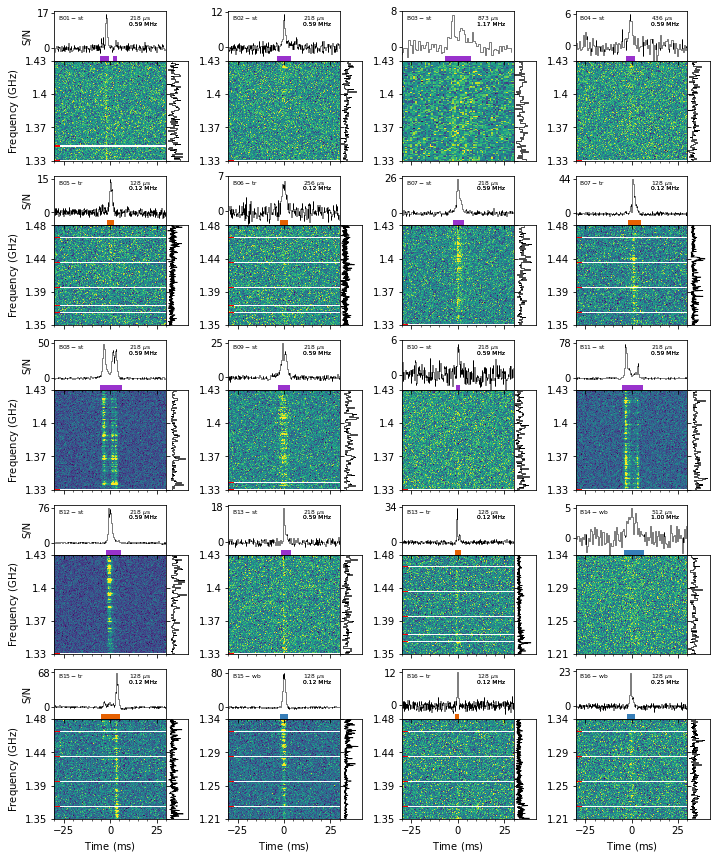

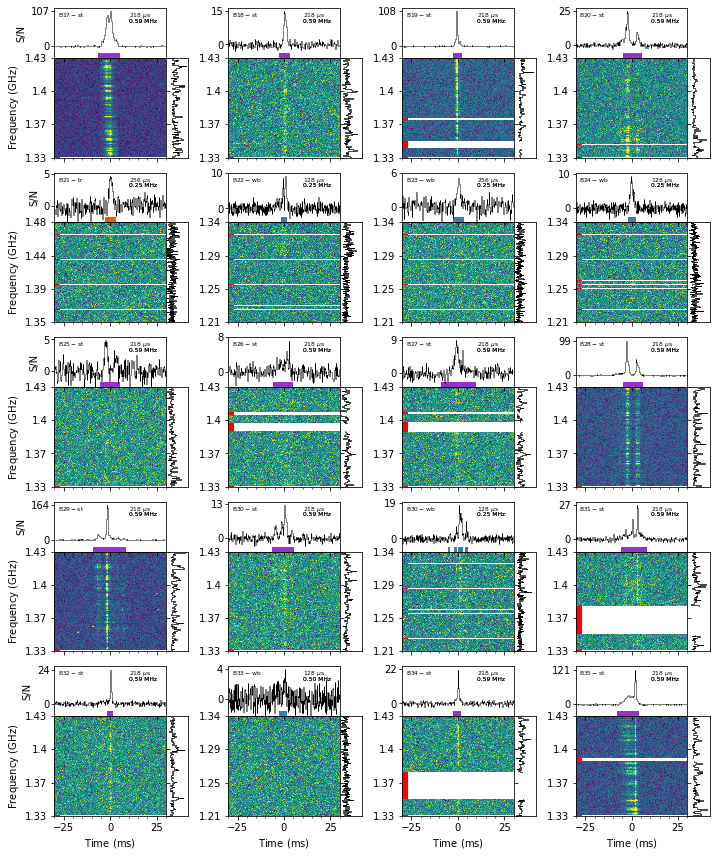

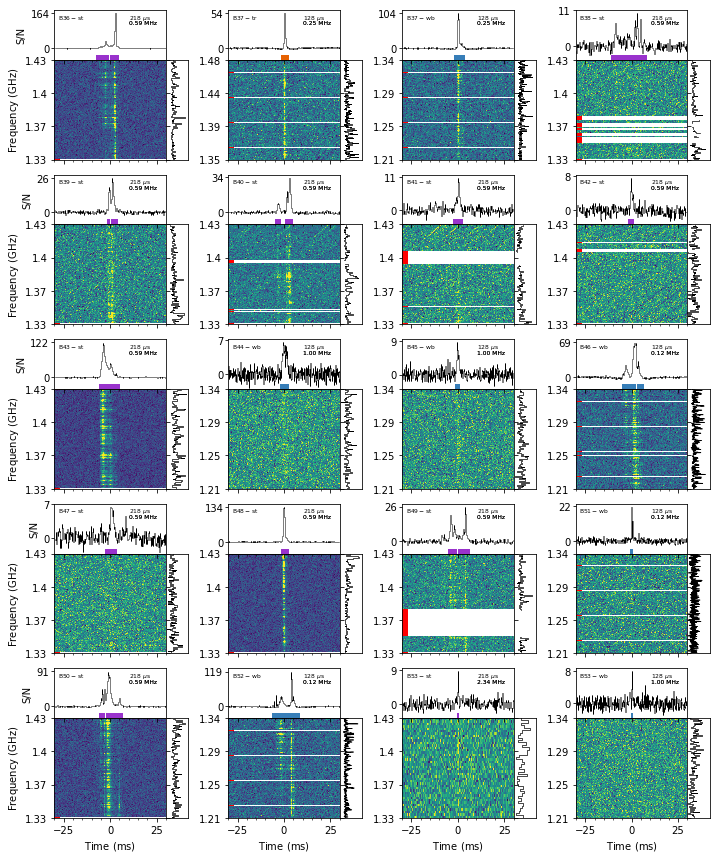

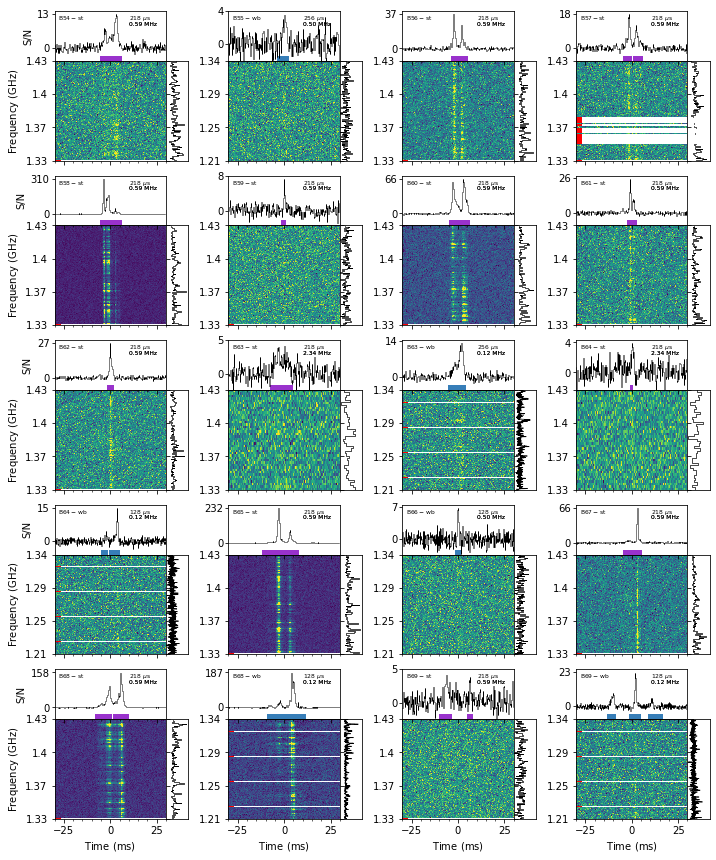

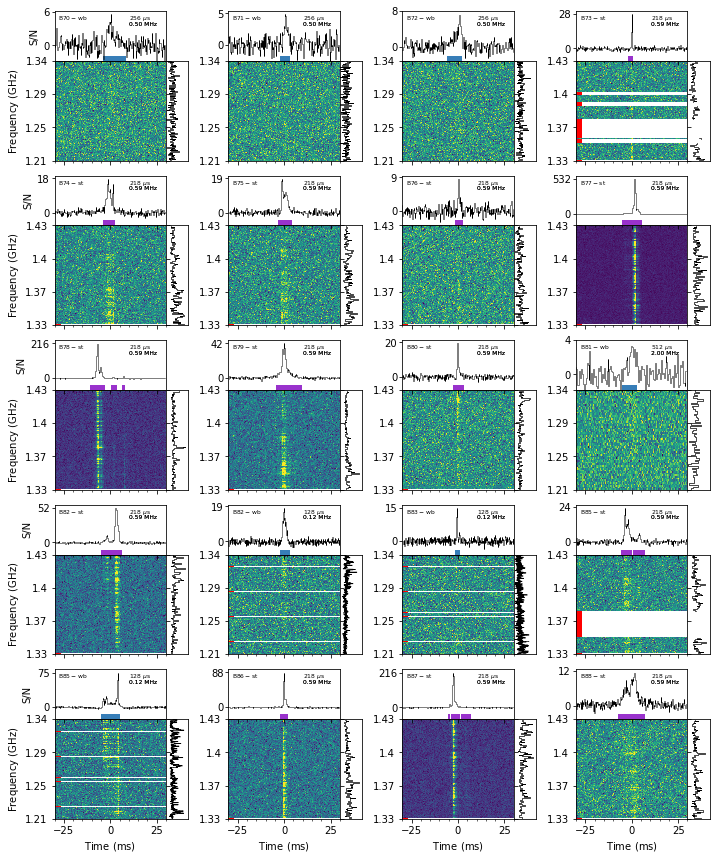

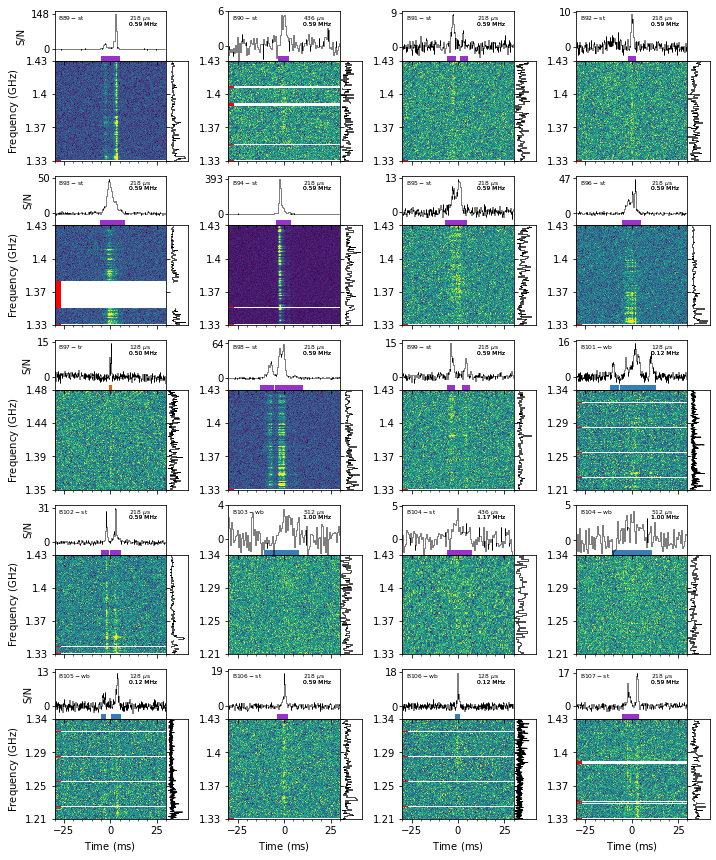

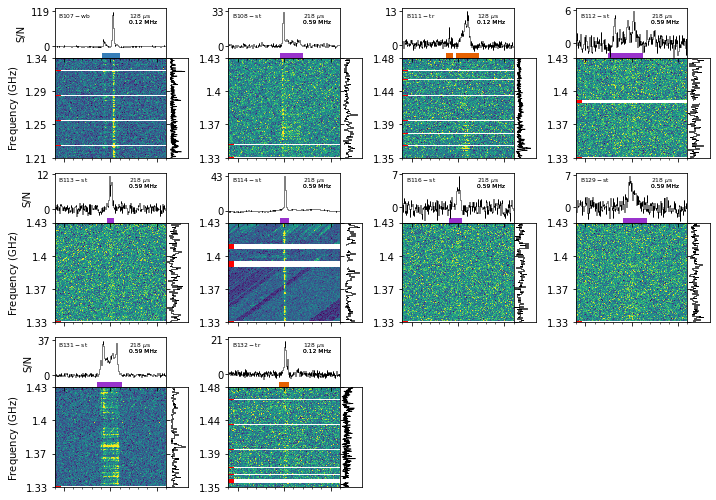

<Figure size 720x864 with 0 Axes>

In [11]:
controller(obs_band="L", width_burst=60)

  0%|          | 0/16 [00:00<?, ?it/s]

--------------------
B100-wb
--------------------
Using new width of 500 ms
Loading in archive file /data1/omar//p11714/sfxc/p11714_wb_no0035.ds.pazi


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:201: UserWarning: FixedFormatter should only be used together with FixedLocator
  6%|▋         | 1/16 [00:00<00:04,  3.23it/s]

Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc
t0 = [1016.64276763] ms
t0 = 248.2038006899951 bins
t_start = [240]; 
t_end = [254]
t_l_bin: 187; t_cent: 248.2038006899951; t_h_bin: 309
After fiddling: t_start = [-8]
t_end=[6]
In time units: t_start = [-32.768]
t_end=[24.576]
x_min = -249.856
x_max = 245.76
index and columns: 0, 4
ncols: 4
--------------------
B109-wb
--------------------
Using new width of 500 ms
Loading in archive file /data1/omar//p11720/sfxc/p11720_wb_no0036.ds.pazi


 12%|█▎        | 2/16 [00:00<00:04,  3.43it/s]

Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc
t0 = [994.45533676] ms
t0 = 242.78694745057226 bins
t_start = [234]; 
t_end = [249]
t_l_bin: 181; t_cent: 242.78694745057226; t_h_bin: 303
After fiddling: t_start = [-8]
t_end=[7]
In time units: t_start = [-32.768]
t_end=[28.672]
x_min = -249.856
x_max = 245.76
index and columns: 1, 4
ncols: 4
--------------------
B110-wb
--------------------
Using new width of 500 ms
Loading in archive file /data1/omar//p11721/sfxc/p11721_wb_no0046.ds.pazi
Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc

... (23 outputs left out)

t0 = [1027.68141521] ms
t0 = 501.7975660206968 bins
t_start = [498]; 
t_end = [510]
t_l_bin: 416; t_cent: 501.7975660206968; t_h_bin: 587
After fiddling: t_start = [-3]
t_end=[9]
In time units: t_start = [-6.144]
t_end=[18.432]
x_min = -174.07999999999998
x_max = 174.07999999999998
index and columns: 13, 4
ncols: 4
--------------------
B127-wb
--------------------
Using new width of 500 ms
Loading in archive file /data1/omar//p11749/sfxc/p11749_wb_no0026.ds.pazi
Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc


 94%|█████████▍| 15/16 [00:03<00:00,  4.30it/s]

t0 = [974.16445776] ms
t0 = 475.66623913983017 bins
t_start = [469]; 
t_end = [478]
t_l_bin: 353; t_cent: 475.66623913983017; t_h_bin: 597
After fiddling: t_start = [-6]
t_end=[3]
In time units: t_start = [-12.288]
t_end=[6.144]
x_min = -249.856
x_max = 247.808
index and columns: 14, 4
ncols: 4
--------------------
B128-wb
--------------------
Using new width of 100 ms
Loading in archive file /data1/omar//p11749/sfxc/p11749_wb_no0030.ds.pazi
Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc
t0 = [ 996.53257501 1003.7799443  1010.62468197 1017.60363018] ms
t0 = 1966.929887882456 bins
t_start = [1939 1953 1968 1979]; 
t_end = [1953 1967 1979 2020]
t_l_bin: 1869; t_cent: 1966.929887882456; t_h_bin: 2064
After fiddling: t_start = [-27 -13   2  13]
t_end=[-13   1  13  54]
In time units: t_start = [-13.824  -6.656   1.024   6.656]
t_end=[-6.656  0.512  6.656 27.648]
x_min = -49.664
x_max = 49.664
index and columns: 15, 4
ncols

/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:447: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:454: UserWarning: Warning: converting a masked element to nan.
  a_min = np.float64(newmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:459: UserWarning: Warning: converting a masked element to nan.
  a_max = np.float64(newmax)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:479: UserWarning: Warning: converting a masked element to nan.
  dtype=scaled_dtype)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:447: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:454: UserWarning: Warning: converting a masked element to nan.
  a_min = np.float64(newmin)
/usr/local/lib/python3.6/dist-pac

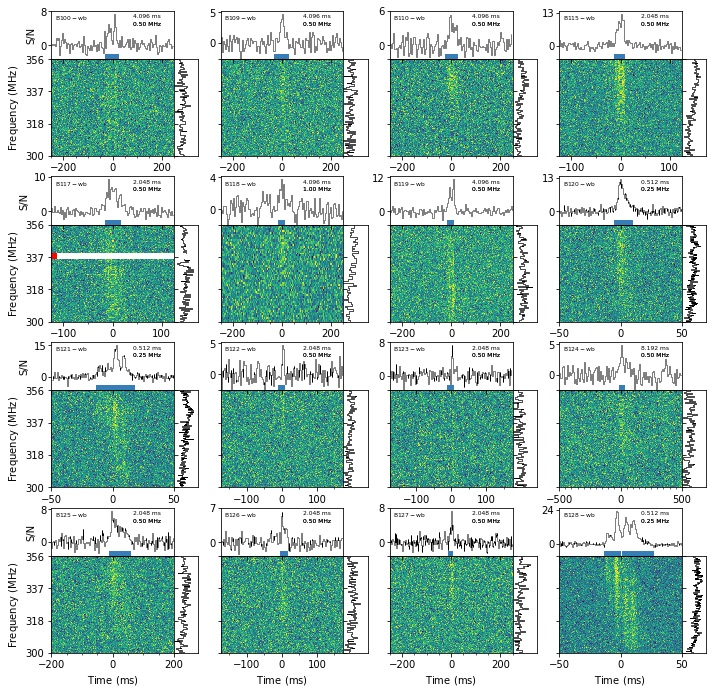

<Figure size 720x864 with 0 Axes>

In [12]:
controller(obs_band="P", width_burst=None)

  8%|▊         | 1/12 [00:00<00:01,  8.38it/s]

--------------------
B08-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59869_5823857.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [208.81715406 213.66982606 215.5538046 ] ms
t0 = 971.3080413849821 bins
t_start = [946 968 981]; 
t_end = [968 980 999]
t_l_bin: 833; t_cent: 971.3080413849821; t_h_bin: 1108
After fiddling: t_start = [-25  -3  10]
t_end=[-3  9 28]
In time units: t_start = [-5.46133333 -0.65536     2.18453333]
t_end=[-0.65536     1.96608     6.11669333]
x_min = -30.14656
x_max = 29.709653333333335
index and columns: 0, 4
--------------------
B15-tr
--------------------
Loading in archive file /data1/omar//f22l01/sfxc/f22l01_tr_no0041.ds.pazi
Archive file is already dedispersed to a DM of 219.3699951171875 pc/cc
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [250.32014112 253.20454041 257.00172429] ms
t0 = 1981.726036735088 bins
t_start = [1941 1964 1998]; 
t_end = [1963 1996 2023]


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
 17%|█▋        | 2/12 [00:00<00:05,  1.98it/s]

t_l_bin: 1747; t_cent: 1981.726036735088; t_h_bin: 2216
After fiddling: t_start = [-40 -17  17]
t_end=[-18  15  42]
In time units: t_start = [-5.12  -2.176  2.176]
t_end=[-2.304  1.92   5.376]
x_min = -29.951999999999998
x_max = 29.951999999999998
index and columns: 1, 4
--------------------
B15-wb
--------------------
Loading in archive file /data1/omar//pcn019/sfxc/pcn019_wb_no0008.ds.pazi
Archive file is already dedispersed to a DM of 219.3699951171875 pc/cc
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [253.27236662] ms
t0 = 1978.6903642039545 bins
t_start = [1963]; 
t_end = [1995]


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
 25%|██▌       | 3/12 [00:01<00:05,  1.67it/s]

t_l_bin: 1744; t_cent: 1978.6903642039545; t_h_bin: 2213
After fiddling: t_start = [-15]
t_end=[17]
In time units: t_start = [-1.92]
t_end=[2.176]
x_min = -29.951999999999998
x_max = 29.951999999999998
index and columns: 2, 4
--------------------
B35-st
--------------------
Loading in archive file /data1/omar//stocke/sfxc/stocke_59877_5565197.ds.pazi
Dedispersing the data to a DM of 219.37 pc/cc
t0 = [200.3074445  204.30730844] ms
t0 = 926.0896749916078 bins
t_start = [891 929]; 
t_end = [929 943]
t_l_bin: 788; t_cent: 926.0896749916078; t_h_bin: 1063
After fiddling: t_start = [-35   3]
t_end=[ 3 17]
In time units: t_start = [-7.64586667  0.65536   ]
t_end=[0.65536    3.71370667]
x_min = -30.14656
x_max = 29.709653333333335
index and columns: 3, 4


... (11 outputs left out)

t_l_bin: 1730; t_cent: 1965.3198270031219; t_h_bin: 2199
After fiddling: t_start = [-90 -51 -14  39]
t_end=[-54 -16  37 102]
In time units: t_start = [-11.52   -6.528  -1.792   4.992]
t_end=[-6.912 -2.048  4.736 13.056]
x_min = -30.08
x_max = 29.823999999999998
index and columns: 9, 4
--------------------
B120-wb
--------------------
Loading in archive file /data1/omar//p11747/sfxc/p11747_wb_no0020.ds.pazi
Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
 92%|█████████▏| 11/12 [00:04<00:00,  2.40it/s]

t0 = [991.47099215] ms
t0 = 1936.4667815405662 bins
t_start = [1925]; 
t_end = [1956]
t_l_bin: 1877; t_cent: 1936.4667815405662; t_h_bin: 1995
After fiddling: t_start = [-11]
t_end=[20]
In time units: t_start = [-5.632]
t_end=[10.24]
x_min = -30.208
x_max = 29.696
index and columns: 10, 4
--------------------
B128-wb
--------------------
Loading in archive file /data1/omar//p11749/sfxc/p11749_wb_no0030.ds.pazi
Archive file is already dedispersed to a DM of 219.6999969482422 pc/cc
Dedispersing the data to a DM of 219.7 pc/cc
t0 = [ 996.53257501 1003.7799443  1010.62468197 1017.60363018] ms
t0 = 1966.929887882456 bins
t_start = [1939 1953 1968 1979]; 
t_end = [1953 1967 1979 2020]
t_l_bin: 1908; t_cent: 1966.929887882456; t_h_bin: 2025
After fiddling: t_start = [-27 -13   2  13]
t_end=[-13   1  13  54]
In time units: t_start = [-13.824  -6.656   1.024   6.656]
t_end=[-6.656  0.512  6.656 27.648]
x_min = -29.696
x_max = 29.696
index and columns: 11, 4


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:193: UserWarning: FixedFormatter should only be used together with FixedLocator
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:447: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:454: UserWarning: Warning: converting a masked element to nan.
  a_min = np.float64(newmin)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:459: UserWarning: Warning: converting a masked element to nan.
  a_max = np.float64(newmax)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:479: UserWarning: Warning: converting a masked element to nan.
  dtype=scaled_dtype)
/usr/local/lib/python3.6/dist-packages/matplotlib/image.py:447: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/usr/local/lib/python3.6/dist-packages/matp

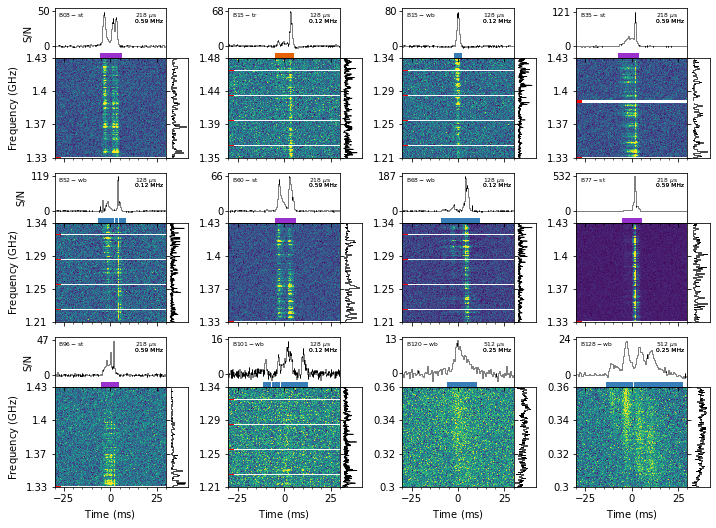

<Figure size 720x864 with 0 Axes>

In [13]:
controller(obs_band="subset", width_burst=60)